In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt 
import seaborn as sns
from database import engine
import joblib

#so the plots apear inside the notebook
%matplotlib inline 

#models from sklearn
from sklearn.ensemble import IsolationForest

#model evaluations
from sklearn.model_selection import train_test_split , cross_val_score
from sklearn.model_selection import RandomizedSearchCV , GridSearchCV
from sklearn.metrics import confusion_matrix , classification_report
from sklearn.metrics import accuracy_score , precision_score , recall_score , f1_score
from sklearn.metrics import RocCurveDisplay


In [2]:
df = pd.read_sql("SELECT * FROM metrics ORDER BY device_id, timestamp", engine)
print(df.shape)


(112333, 11)


In [3]:
df.head()

,metrics_id,device_id,timestamp,cpu,memory,temperature,latency,packet_loss,traffic,interface_errors,is_anomaly
0,12,1,2026-09-10 19:00:36.355737,37.342804,45.760672,40.184116,1.960100,0.140178,45.159617,0,False
1,25,1,2026-09-10 19:05:36.355737,36.289998,47.476585,39.825837,1.590967,0.177068,48.719336,0,False
2,38,1,2026-09-10 19:10:36.355737,39.031097,47.964285,39.730898,1.629247,0.251080,44.624240,0,False
3,51,1,2026-09-10 19:15:36.355737,41.627376,47.828061,40.290853,1.671165,0.319733,47.839795,0,False
4,64,1,2026-09-10 19:20:36.355737,39.404915,47.049262,40.058943,2.001904,0.293688,46.924823,0,False


In [46]:
df.is_anomaly.value_counts()

is_anomaly
False    110313
True       2020
Name: count, dtype: int64

(array([  0.,  10.,  20.,  30.,  40.,  50.,  60.,  70.,  80.,  90., 100.]),
 [Text(0.0, 0, '0'),
  Text(10.0, 0, '10'),
  Text(20.0, 0, '20'),
  Text(30.0, 0, '30'),
  Text(40.0, 0, '40'),
  Text(50.0, 0, '50'),
  Text(60.0, 0, '60'),
  Text(70.0, 0, '70'),
  Text(80.0, 0, '80'),
  Text(90.0, 0, '90'),
  Text(100.0, 0, '100')])

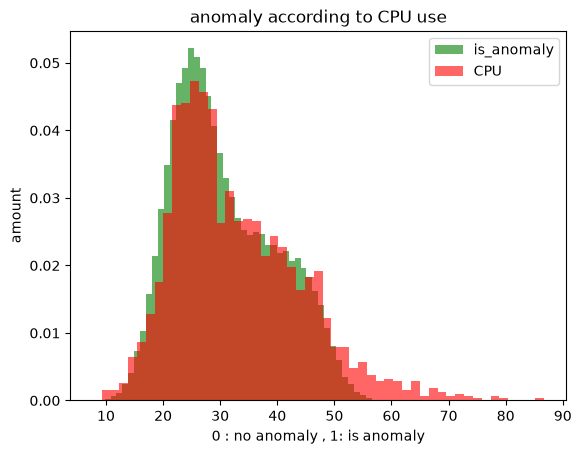

In [6]:
plt.hist(df.loc[~df.is_anomaly, "cpu"], bins=50, alpha=0.6, density=True, color="green", label="normal")
plt.hist(df.loc[df.is_anomaly, "cpu"], bins=50, alpha=0.6, density=True, color="red", label="anomaly")

plt.title("anomaly according to CPU use")
plt.xlabel("0 : no anomaly , 1: is anomaly")
plt.ylabel("amount")
plt.legend(["is_anomaly" , "CPU"])
plt.xticks(rotation = 0)

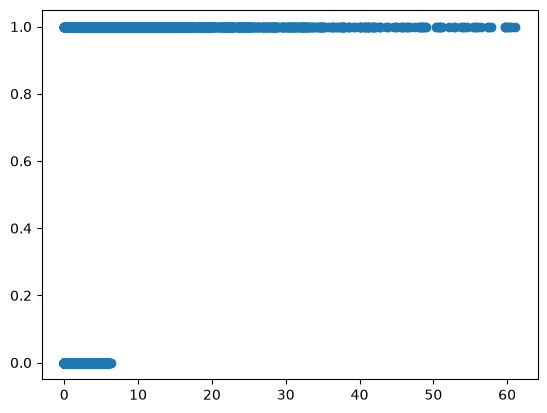

In [11]:
plt.scatter(df.latency , df.is_anomaly)


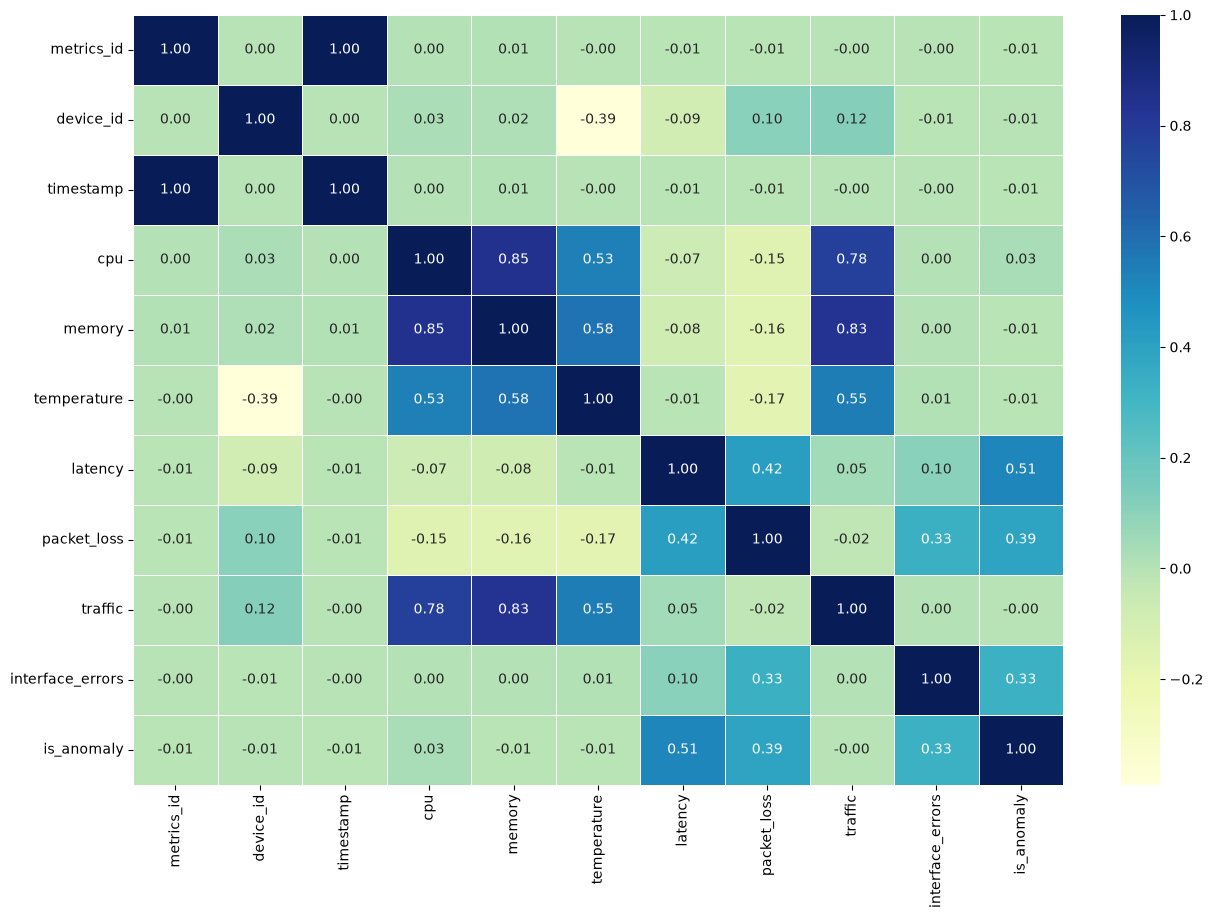

In [48]:
corr_matrix = df.corr()
fig , ax = plt.subplots( figsize = (15 , 10))
ax = sns.heatmap(corr_matrix , 
                 annot = True, 
                 linewidths=0.5,
                 fmt =".2f",
                 cmap = "YlGnBu");

<Axes: >

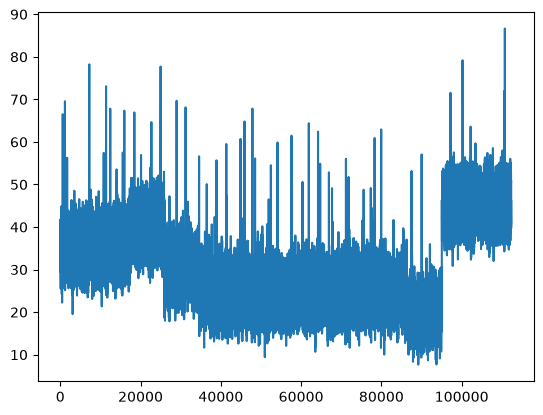

In [49]:
df.cpu.plot()

<Axes: >

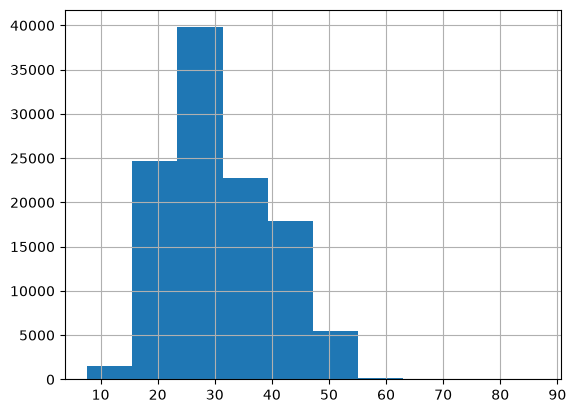

In [50]:
df.cpu.hist()

<Axes: >

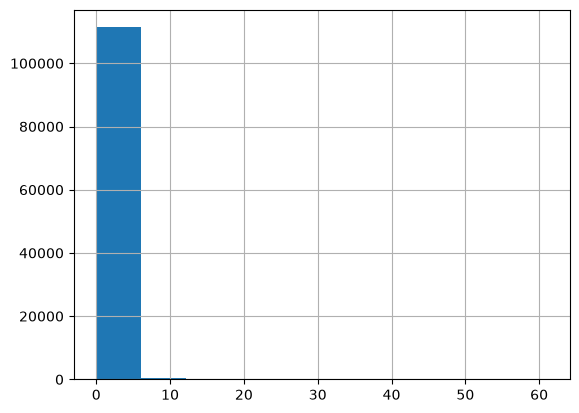

In [51]:
df.latency.hist()

<Axes: >

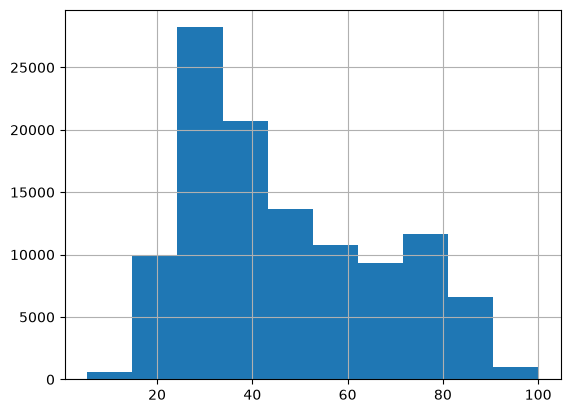

In [52]:
df.traffic.hist()

In [ ]:
features = ["cpu", "memory", "temperature", "latency",
            "packet_loss", "traffic", "interface_errors"]


0.8459573049273463
0.0028451669999739536


In [16]:
print(df[features].corr().loc["cpu", "memory"])
print(df[df.device_id == 1][features].corr().loc["cpu", "memory"])

0.8459573049273463
0.05185743772678654


In [13]:
df[df.device_id == 5][features].corr().round(2)


,cpu,memory,temperature,latency,packet_loss,traffic,interface_errors
cpu,1.00,0.00,0.01,-0.00,0.02,-0.01,0.03
memory,0.00,1.00,-0.02,-0.02,-0.00,0.02,-0.01
temperature,0.01,-0.02,1.00,-0.00,-0.02,-0.07,0.04
latency,-0.00,-0.02,-0.00,1.00,0.38,-0.02,0.15
packet_loss,0.02,-0.00,-0.02,0.38,1.00,-0.03,0.42
traffic,-0.01,0.02,-0.07,-0.02,-0.03,1.00,-0.01
interface_errors,0.03,-0.01,0.04,0.15,0.42,-0.01,1.00


In [17]:
x = df[features]
y = df["is_anomaly"]

In [18]:
df = df.sort_values("timestamp")
split = int(len(df) * 0.8)

train, test = df.iloc[:split], df.iloc[split:]
x_train, y_train = train[features], train["is_anomaly"]
x_test, y_test = test[features], test["is_anomaly"]

In [57]:
models = {"Logistic Regression" : LogisticRegression(max_iter=1500) , 
          "Random Forest Classifier" : RandomForestClassifier()}

def fit_and_score(models, x_train, x_test, y_train, y_test):
    results = {}
    for name, model in models.items():
        model.fit(x_train, y_train)
        preds = model.predict(x_test)
        results[name] = {
            "precision": precision_score(y_test, preds, zero_division=0),
            "recall": recall_score(y_test, preds, zero_division=0),
            "f1": f1_score(y_test, preds, zero_division=0),
        }
        print(name)
        print(classification_report(y_test, preds, zero_division=0))
    return pd.DataFrame(results).T

In [58]:
model_scores = fit_and_score(models=models , x_train = x_train , x_test=x_test , y_train= y_train , y_test=y_test)


Logistic Regression
              precision    recall  f1-score   support

       False       0.99      1.00      1.00     22060
        True       0.99      0.64      0.78       407

    accuracy                           0.99     22467
   macro avg       0.99      0.82      0.89     22467
weighted avg       0.99      0.99      0.99     22467

Random Forest Classifier
              precision    recall  f1-score   support

       False       1.00      1.00      1.00     22060
        True       0.99      0.74      0.85       407

    accuracy                           1.00     22467
   macro avg       0.99      0.87      0.92     22467
weighted avg       1.00      1.00      0.99     22467



In [36]:
if_models = {}

df = df.sort_values("timestamp")
split = int(len(df)*0.8)
train , test = df.iloc[:split] , df.iloc[split:].copy()

test["predicted"] = False
for device_id ,group in train.groupby("device_id"):
    iso_model = IsolationForest(contamination=0.0165 , random_state=42)
    iso_model.fit(group[features])
    t = test[test.device_id == device_id]
    test.loc[t.index , "predicted"] = (iso_model.predict(t[features]) == -1)
    if_models[device_id] = iso_model
    
print(classification_report(test["is_anomaly"] , test["predicted"]))
joblib.dump({"models" : if_models , "features" :features} , "IsolationForest_model.joblib")
print(f"trained {len(if_models)} models and saved them")

              precision    recall  f1-score   support

       False       0.99      0.99      0.99     22060
        True       0.63      0.52      0.57       407

    accuracy                           0.99     22467
   macro avg       0.81      0.76      0.78     22467
weighted avg       0.98      0.99      0.99     22467

trained 13 models and saved them
